# Chapitre 6 - Lab : Redis Cluster, un partitionnement par hachage grandeur nature

Ce lab confronte le cours à un vrai système : **Redis Cluster** (Redis 7). Son schéma
est exactement l'un de ceux du chapitre : l'espace des clés est découpé une fois pour
toutes en **16 384 slots** (un nombre fixe de partitions), chaque
clé tombe dans le slot `CRC16(clé) mod 16384`, et chaque nœud maître possède un
ensemble de slots. Le routage est confié au **client** : un nœud qui reçoit une clé
qu'il ne possède pas répond par une redirection (`MOVED`), à charge pour le client de
tenir sa carte à jour. Nous allons :

1. créer un cluster de trois maîtres et lire sa carte des slots ;
2. vérifier notre propre CRC16 contre celui du serveur et mesurer la répartition des clés ;
3. observer les redirections `MOVED` et comparer deux façons de tenir la carte à jour ;
4. regrouper des clés avec les **hash tags**, et en voir le revers (le point chaud) ;
5. ajouter un quatrième nœud et **mesurer** la fraction de clés déplacées ;
6. migrer un slot à la main pour voir la **période de bascule** (redirections `ASK`) ;
7. observer une clé chaude depuis les compteurs des nœuds, puis la saler.

**Démarrer et arrêter les services** (depuis la racine du dépôt) :

```bash
docker compose -f docker/partitioning/compose.yml -p ddia_partitioning up -d     # démarrer
docker compose -f docker/partitioning/compose.yml -p ddia_partitioning down -v   # arrêter et effacer
```

Les quatre nœuds Redis partagent le réseau de la machine : ils écoutent sur les ports
**10701 à 10704** (bus de cluster sur 10711 à 10714) et s'annoncent sous l'adresse
`127.0.0.1`, si bien que les redirections renvoient vers des adresses joignables depuis
ce notebook. Le notebook pilote `redis-cli` dans un conteneur via `docker exec`, et se
rejoue autant de fois qu'on veut : il remet les nœuds à zéro avant de créer le cluster.

In [1]:
import subprocess
import time
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import redis
from redis.cluster import RedisCluster
from redis.exceptions import AskError, MovedError, ResponseError

from ddia import partitioning as P
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, COLORS, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 100)
fmt = lambda v: f"{v:,.0f}".replace(",", " ")      # 1234567 -> « 1 234 567 »

PORTS = [10701, 10702, 10703, 10704]
NODE_COLOR = {10701: INDIGO, 10702: TEAL, 10703: AMBER, 10704: ROSE}
N_SLOTS = 16384


def node(port):
    """Connexion simple (non « cluster ») à un nœud."""
    return redis.Redis(host="127.0.0.1", port=port, decode_responses=True)


def cli(*args, check=True):
    """Lance redis-cli dans le conteneur du premier nœud (réseau de l'hôte)."""
    r = subprocess.run(["docker", "exec", "ddia_partitioning_r1", "redis-cli", *args],
                       capture_output=True, text=True)
    if check and r.returncode != 0:
        raise RuntimeError(r.stdout[-500:] + r.stderr[-500:])
    return r.stdout


for port in PORTS:
    for essai in range(30):
        try:
            assert node(port).ping()
            break
        except redis.ConnectionError:
            time.sleep(1)
    else:
        raise RuntimeError(f"le nœud {port} ne répond pas : avez-vous lancé docker compose up ?")
print(node(10701).info("server")["redis_version"], "sur les ports", PORTS)

7.4.11 sur les ports [10701, 10702, 10703, 10704]


**Création du cluster.** On remet les quatre nœuds à zéro (`FLUSHALL` puis
`CLUSTER RESET HARD`, qui leur fait oublier tout cluster précédent), puis `redis-cli
--cluster create` répartit les 16 384 slots entre les **trois premiers** nœuds, sans
répliques (la réplication est le sujet du chapitre 5 ; on l'ignore ici
comme le fait le chapitre). Le quatrième nœud reste à l'écart : il servira au
rééquilibrage de la section 5. Les nœuds apprennent l'existence les uns des autres par
un protocole de **gossip** sur le bus de cluster : il faut attendre qu'ils soient tous
d'accord avant de travailler.

In [2]:
def wait_cluster(ports, timeout=60):
    """Attend que chaque nœud connaisse tous les autres et déclare le cluster opérationnel."""
    t0 = time.time()
    while time.time() - t0 < timeout:
        infos = [node(p).cluster("info") for p in ports]
        if all(i["cluster_state"] == "ok" and int(i["cluster_known_nodes"]) == len(ports) for i in infos):
            return time.time() - t0
        time.sleep(0.2)
    raise TimeoutError("le cluster ne converge pas")


for port in PORTS:
    n = node(port)
    n.flushall()
    n.execute_command("CLUSTER", "RESET", "HARD")

out = cli("--cluster", "create", *[f"127.0.0.1:{p}" for p in PORTS[:3]],
          "--cluster-replicas", "0", "--cluster-yes")
print("\n".join(l for l in out.splitlines() if l.startswith("[OK]")))
print(f"convergence du gossip : {wait_cluster(PORTS[:3]):.1f} s")

[OK] All nodes agree about slots configuration.
[OK] All 16384 slots covered.


convergence du gossip : 4.0 s


## 1. Les 16 384 slots : un nombre fixe de partitions (section *Rebalancing Partitions*, *Fixed number of partitions*)

Le livre décrit une stratégie très répandue : créer dès le départ **beaucoup plus de
partitions que de nœuds**, puis ne jamais changer l'affectation
clé -> partition ; seule bouge l'affectation
partition -> nœud. Redis Cluster en est une incarnation directe,
avec 16 384 slots. Lisons la carte que le cluster vient de construire (`CLUSTER SLOTS`
donne des plages contiguës de slots et leur propriétaire).

In [3]:
def slot_owners(port=10701):
    """Carte complète : port du nœud propriétaire de chacun des 16 384 slots."""
    owners = np.zeros(N_SLOTS, dtype=np.int64)
    for start, end, master, *_ in node(port).execute_command("CLUSTER", "SLOTS"):
        owners[start:end + 1] = master[1]
    return owners


def slot_ranges(port=10701):
    rows = [{"premier slot": s, "dernier slot": e, "nœud": m[1], "slots": e - s + 1}
            for s, e, m, *_ in node(port).execute_command("CLUSTER", "SLOTS")]
    return pd.DataFrame(rows).sort_values("premier slot").reset_index(drop=True)


owners3 = slot_owners()
slot_ranges()

,premier slot,dernier slot,nœud,slots
0,0,5460,10701,5461
1,5461,10922,10702,5462
2,10923,16383,10703,5461


Trois plages contiguës d'environ 5 461 slots chacune. Le schéma d'ensemble : les slots
sont attribués aux nœuds, les nœuds bavardent entre eux sur le bus de cluster, et le
client parle directement au nœud qui possède le slot de sa clé.

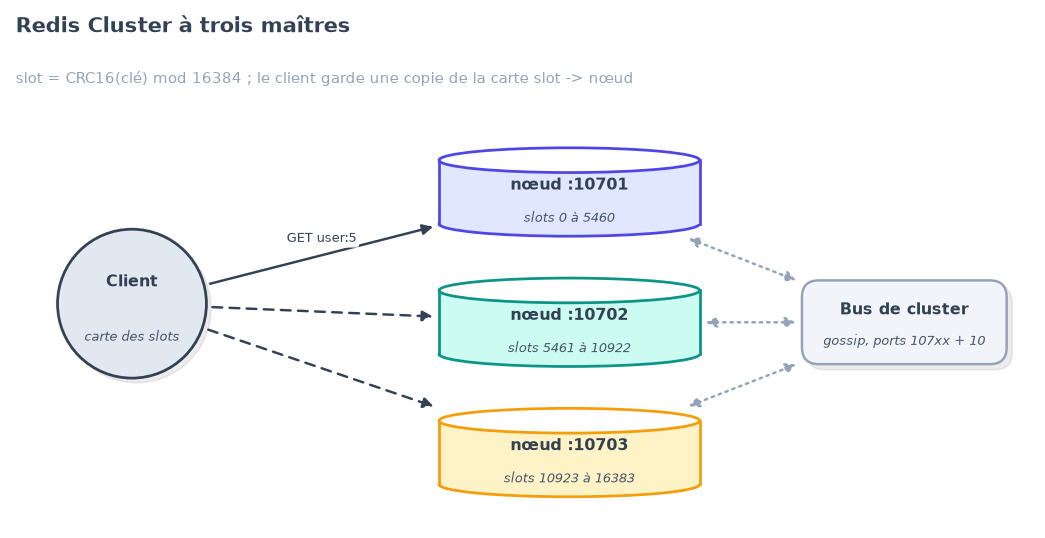

In [4]:
d = Diagram(11, 4.6, title="Redis Cluster à trois maîtres",
            subtitle="slot = CRC16(clé) mod 16384 ; le client garde une copie de la carte slot -> nœud")
d.box("client", 1.3, 2.4, "Client", sub="carte des slots", kind="user", w=1.6, color=SLATE)
ys = [3.6, 2.2, 0.8]
for (port, y), (_, row) in zip(zip(PORTS[:3], ys), slot_ranges().iterrows()):
    d.box(f"n{port}", 6.0, y, f"nœud :{port}", sub=f"slots {row['premier slot']} à {row['dernier slot']}",
          color=NODE_COLOR[port], kind="db", w=2.8, h=0.95)
d.box("bus", 9.6, 2.2, "Bus de cluster", sub="gossip, ports 107xx + 10", color=GRAY, w=2.2)
d.arrow("client", "n10701", "GET user:5")
d.arrow("client", "n10702", rad=0.0, style="dashed")
d.arrow("client", "n10703", style="dashed")
for port in PORTS[:3]:
    d.arrow(f"n{port}", "bus", style="dotted", color=GRAY, both=True)
d.show()

Pourquoi 16 384 ? C'est un compromis que le livre évoque : assez de
partitions pour répartir finement la charge entre beaucoup de
nœuds (Redis recommande au plus un millier de maîtres, soit au moins 16 slots chacun),
mais assez peu pour que la carte reste petite. Elle tient en un bitmap de
16 384 bits = **2 Kio**, que chaque nœud joint à ses messages de gossip. La limite
annoncée par le livre s'applique aussi : on ne pourra jamais avoir plus de nœuds
maîtres que de slots.

> **À retenir.** Redis Cluster applique la stratégie du nombre fixe de
> partitions : 16 384 slots créés une fois pour toutes, et une carte
> slot -> nœud qui, seule, change lors d'un rééquilibrage.

## 2. CRC16 et répartition des clés (section *Partitioning by Hash of Key*)

La fonction de hachage n'a pas besoin d'être cryptographique, mais elle doit être
**identique partout** : chez tous les clients, dans tous les langages, sur tous les
nœuds. Redis utilise un CRC16 (variante XMODEM), que nous avons réimplémenté dans
`ddia.partitioning.redis_slot`. Vérifions-le contre le serveur (`CLUSTER KEYSLOT`) sur un
échantillon de clés variées.

In [5]:
rng = np.random.default_rng(7)
sample = [f"user:{i}" for i in rng.integers(0, 10**6, 400)] + \
         [f"session:{rng.integers(10**9)}" for _ in range(300)] + \
         [f"{{user:{i}}}:panier" for i in range(300)]
pipe = node(10701).pipeline(transaction=False)
for k in sample:
    pipe.execute_command("CLUSTER", "KEYSLOT", k)
server = pipe.execute()
mine = [P.redis_slot(k) for k in sample]
print(f"{sum(a == b for a, b in zip(mine, server))} / {len(sample)} slots identiques à ceux du serveur")
pd.DataFrame({"clé": sample[:3] + sample[-2:], "slot (ddia)": mine[:3] + mine[-2:],
              "slot (serveur)": server[:3] + server[-2:]})

1000 / 1000 slots identiques à ceux du serveur


,clé,slot (ddia),slot (serveur)
0,user:944904,10938,10938
1,user:625095,8352,8352
2,user:684179,1289,1289
3,{user:298}:panier,1692,1692
4,{user:299}:panier,5821,5821


Les 1 000 slots coïncident. Chargeons maintenant 100 000 clés `user:0` à `user:99999`
avec le client « cluster » de redis-py (il découpe le pipeline par nœud), puis
comptons les clés présentes sur chaque nœud (`DBSIZE`) et par slot.

100 000 clés écrites en 0.8 s


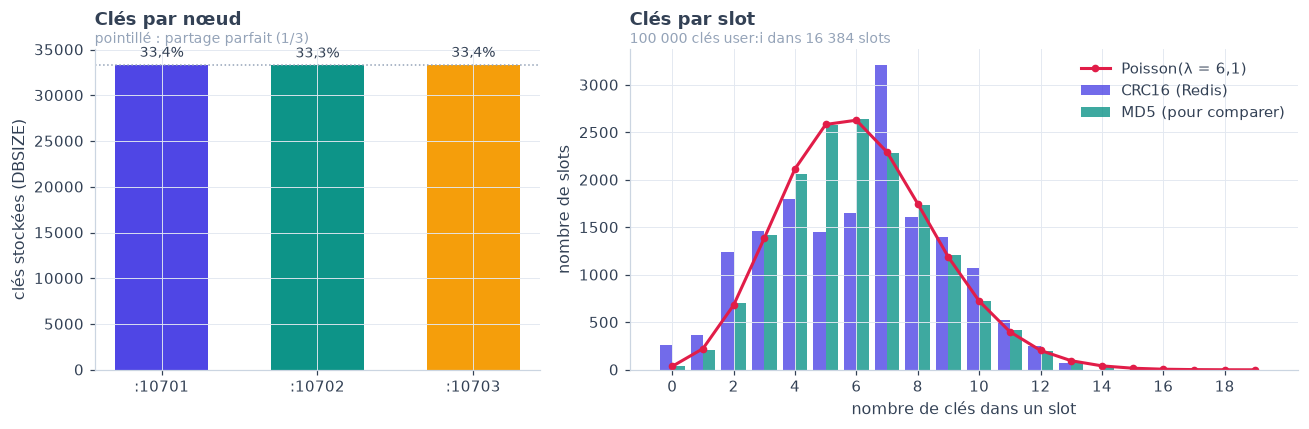

,hachage,slots vides,écart-type des clés par slot
0,CRC16 (Redis),264,2.763
1,MD5,37,2.465
2,Poisson (théorie),37,2.471


In [6]:
N_KEYS = 100_000
KEYS = [f"user:{i}" for i in range(N_KEYS)]
rc = RedisCluster(host="127.0.0.1", port=10701, decode_responses=True)
t0 = time.time()
pipe = rc.pipeline()
for k in KEYS:
    pipe.set(k, "profil")
pipe.execute()
print(f"{fmt(N_KEYS)} clés écrites en {time.time() - t0:.1f} s")

key_slot = np.array([P.redis_slot(k) for k in KEYS])
per_slot = np.bincount(key_slot, minlength=N_SLOTS)
dbsize = {p: node(p).dbsize() for p in PORTS[:3]}

fig, axes = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1, 1.5]})
ax = axes[0]
bars = ax.bar([f":{p}" for p in dbsize], dbsize.values(), color=[NODE_COLOR[p] for p in dbsize], width=0.6)
ax.bar_label(bars, labels=[f"{v / N_KEYS:.1%}".replace(".", ",") for v in dbsize.values()], padding=3, fontsize=9)
ax.axhline(N_KEYS / 3, color=GRAY, ls=":", lw=1)
ax.set_ylabel("clés stockées (DBSIZE)")
ax.set_title("Clés par nœud")
subtitle(ax, "pointillé : partage parfait (1/3)")
ax = axes[1]
md5_slot = np.array([P.stable_hash(kk) % N_SLOTS for kk in KEYS])
per_slot_md5 = np.bincount(md5_slot, minlength=N_SLOTS)
k = np.arange(max(per_slot.max(), per_slot_md5.max()) + 1)
ax.bar(k - 0.2, np.bincount(per_slot, minlength=k.size), width=0.4, color=INDIGO, alpha=0.8, label="CRC16 (Redis)")
ax.bar(k + 0.2, np.bincount(per_slot_md5, minlength=k.size), width=0.4, color=TEAL, alpha=0.8, label="MD5 (pour comparer)")
lam = N_KEYS / N_SLOTS
from math import factorial
pois = np.array([N_SLOTS * np.exp(-lam) * lam ** i / factorial(i) for i in k])
ax.plot(k, pois, "o-", color=ROSE, ms=4, label=f"Poisson(λ = {lam:.1f})".replace(".", ","))
ax.set_xticks(k[::2])
ax.set_xlabel("nombre de clés dans un slot")
ax.set_ylabel("nombre de slots")
ax.set_title("Clés par slot")
subtitle(ax, f"{fmt(N_KEYS)} clés user:i dans {fmt(N_SLOTS)} slots")
ax.legend()
finish(fig)
plt.show()
pd.DataFrame({"hachage": ["CRC16 (Redis)", "MD5", "Poisson (théorie)"],
              "slots vides": [(per_slot == 0).sum(), (per_slot_md5 == 0).sum(), round(N_SLOTS * np.exp(-lam))],
              "écart-type des clés par slot": [per_slot.std(), per_slot_md5.std(), np.sqrt(lam)]})

Deux constats. **Par nœud**, la répartition est excellente : un tiers des clés à
quelques dixièmes de point près. **Par slot**, en revanche, l'histogramme du CRC16 est
bien plus irrégulier que la loi de Poisson de moyenne 6,1 qu'on attendrait d'un hachage
« aléatoire » (et que MD5 suit fidèlement) : des pics à certaines valeurs, plus de
slots presque vides, un écart-type plus grand. Un CRC est une somme de contrôle
**linéaire**, pas une fonction de mélange : des clés qui ne diffèrent que par quelques
chiffres produisent des motifs réguliers. Cela n'a aucune importance ici, parce que
chaque nœud agrège plus de 5 000 slots et que les irrégularités se compensent : la
granularité fine rattrape la qualité médiocre du hachage. C'est l'argument du
livre en faveur du hachage : il **détruit l'ordre** des clés (une requête de plage
`user:100` à `user:200` toucherait tous les nœuds), mais il répartit uniformément.

> **À retenir.** Un CRC16 n'est pas un hachage parfait (répartition par slot irrégulière),
> mais avec des milliers de slots par nœud les irrégularités se compensent : la charge
> par nœud est équilibrée à quelques dixièmes de point près.

## 3. Le client informé et les redirections `MOVED` (section *Request Routing*)

Le livre distingue trois architectures de routage : (1) n'importe quel nœud accepte la
requête et la relaie, (2) une couche de routage dédiée, (3) un client qui connaît la
carte et va droit au bon nœud. Redis Cluster choisit la troisième, avec un filet de
sécurité : un nœud ne relaie **jamais** ; s'il ne possède pas le slot, il répond
`MOVED <slot> <adresse>`. Essayons avec une connexion ordinaire au nœud 10701.

In [7]:
plain = node(10701)
for key in ["user:1", "user:2", "user:3", "user:4"]:
    try:
        plain.get(key)
        print(f"{key:8s} slot {P.redis_slot(key):5d} -> servi par :10701")
    except MovedError as e:
        print(f"{key:8s} slot {e.slot_id:5d} -> MOVED vers {e.host}:{e.port}")

user:1   slot 10778 -> MOVED vers 127.0.0.1:10702
user:2   slot  6777 -> MOVED vers 127.0.0.1:10702
user:3   slot  2648 -> servi par :10701
user:4   slot 15039 -> MOVED vers 127.0.0.1:10703


Le diagramme espace-temps d'une requête mal adressée : deux allers-retours au lieu
d'un, et le client corrige sa carte au passage.

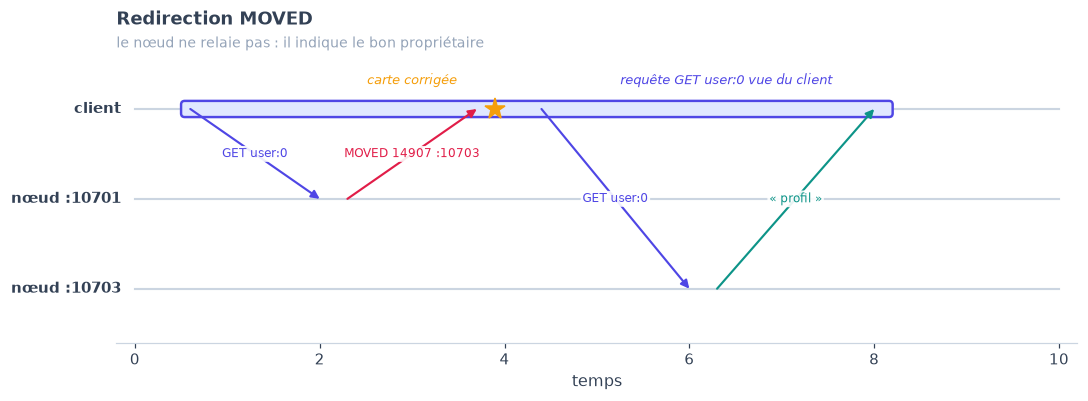

In [8]:
k_demo = next(k for k in KEYS if owners3[P.redis_slot(k)] != 10701)
s_demo, o_demo = P.redis_slot(k_demo), int(owners3[P.redis_slot(k_demo)])
st = SpaceTime(["client", "nœud :10701", f"nœud :{o_demo}"], t_max=10,
               title="Redirection MOVED", subtitle="le nœud ne relaie pas : il indique le bon propriétaire")
st.op("client", 0.5, 8.2, "", color=INDIGO)
st.note(6.4, "client", f"requête GET {k_demo} vue du client", dy=0.32, color=INDIGO)
st.msg("client", 0.6, "nœud :10701", 2.0, f"GET {k_demo}", color=INDIGO)
st.msg("nœud :10701", 2.3, "client", 3.7, f"MOVED {s_demo} :{o_demo}", color=ROSE)
st.event("client", 3.9, "", kind="star")
st.note(3.0, "client", "carte corrigée", dy=0.32, color=AMBER)
st.msg("client", 4.4, f"nœud :{o_demo}", 6.0, f"GET {k_demo}", color=INDIGO)
st.msg(f"nœud :{o_demo}", 6.3, "client", 8.0, "« profil »", color=TEAL)
st.show()

Le schéma utilise une vraie clé, `user:0`, dont le slot (14 907) n'appartient pas au
nœud 10701. Un client
« cluster » charge la carte au démarrage (`CLUSTER SLOTS`) et n'est redirigé que si elle
est périmée. Mais **que faire d'un `MOVED` ?** Deux politiques sont possibles :
corriger seulement le slot indiqué, ou recharger toute la carte. Comparons-les avec un
mini-client qui commence avec une carte fausse (il croit que tout est sur 10701), sur
3 000 lectures de clés aléatoires.

In [9]:
class MiniClient:
    """Client informé minimal : carte locale slot -> port, gestion des MOVED."""

    def __init__(self, refresh, initial_map):
        self.refresh = refresh                      # "slot" ou "carte"
        self.map = np.array(initial_map)
        self.conns = {p: node(p) for p in PORTS}
        self.redirects = 0
        self.reloads = 0

    def get(self, key):
        slot = P.redis_slot(key)
        for _ in range(5):
            try:
                return self.conns[int(self.map[slot])].get(key)
            except MovedError as e:
                self.redirects += 1
                if self.refresh == "carte":
                    self.map = slot_owners()
                    self.reloads += 1
                else:
                    self.map[e.slot_id] = e.port
        raise RuntimeError("trop de redirections")


reads = [KEYS[i] for i in rng.integers(0, N_KEYS, 3000)]
curves, stats = {}, []
for refresh in ["slot", "carte"]:
    c = MiniClient(refresh, np.full(N_SLOTS, 10701))
    hist = []
    for k in reads:
        assert c.get(k) == "profil"
        hist.append(c.redirects)
    curves[refresh] = hist
    stats.append({"politique": refresh, "redirections": c.redirects, "rechargements de carte": c.reloads})
pd.DataFrame(stats)

,politique,redirections,rechargements de carte
0,slot,1783,0
1,carte,1,1


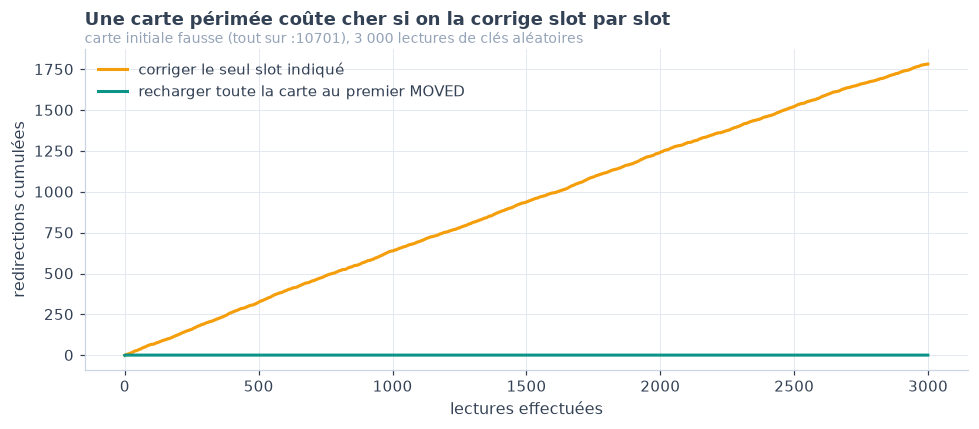

In [10]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(curves["slot"], color=AMBER, label="corriger le seul slot indiqué")
ax.plot(curves["carte"], color=TEAL, label="recharger toute la carte au premier MOVED")
ax.set_xlabel("lectures effectuées")
ax.set_ylabel("redirections cumulées")
ax.set_title("Une carte périmée coûte cher si on la corrige slot par slot")
subtitle(ax, "carte initiale fausse (tout sur :10701), 3 000 lectures de clés aléatoires")
ax.legend()
plt.tight_layout(); plt.show()

Corriger slot par slot coûte une redirection pour presque chaque slot distinct que l'on
touche et qui n'est pas sur 10701 : avec 3 000 lectures sur 16 384 slots, on rencontre
presque toujours un slot neuf (environ 91 % des lectures), dont deux tiers ne sont pas
sur 10701, d'où environ 60 % de lectures redirigées. Recharger
la carte entière (2 Kio d'information) règle le problème en **une** redirection. C'est
ce que font les clients réels : un `MOVED` est le signe que la carte a changé, et un
changement concerne en général des milliers de slots à la fois.

Que coûte une redirection ? Mesurons le temps de réponse d'un `GET` bien adressé et
d'un `GET` systématiquement mal adressé (avec la même connexion locale : seul compte ici
le nombre d'allers-retours).

In [11]:
good = MiniClient("carte", slot_owners())
bad = MiniClient("slot", np.full(N_SLOTS, 10701))
probe = [k for k in reads if owners3[P.redis_slot(k)] != 10701][:1500]


def timed(fn, keys):
    out = []
    for k in keys:
        t = time.perf_counter()
        fn(k)
        out.append((time.perf_counter() - t) * 1e6)
    return np.array(out)


t_good = timed(good.get, probe)


def always_stale(k):
    bad.map[:] = 10701                              # on « oublie » la correction à chaque fois
    return bad.get(k)


t_bad = timed(always_stale, probe)
print(f"médiane bien adressé : {np.median(t_good):.0f} µs ; avec MOVED : {np.median(t_bad):.0f} µs "
      f"(× {np.median(t_bad) / np.median(t_good):.1f})")

médiane bien adressé : 21 µs ; avec MOVED : 43 µs (× 2.1)


Sur une seule machine, un aller-retour coûte quelques dizaines de microsecondes et la
redirection double à peu près le temps de réponse ; dans un centre de données, où un
aller-retour vaut plutôt 0,2 à 0,5 ms, c'est la même proportion. Le schéma « client
informé » n'a donc d'intérêt que si la carte est presque toujours juste, ce qui est le
cas tant que le cluster ne se rééquilibre pas (section 5).

> **À retenir.** Redis Cluster route côté client ; le nœud ne relaie pas mais redirige.
> Un client sérieux recharge toute la carte au premier `MOVED` : le coût d'une carte
> périmée est alors d'une redirection, pas d'une par slot.

## 4. Les hash tags : regrouper des clés, au risque du point chaud (sections *Partitioning by Hash of Key* et *Skewed Workloads and Relieving Hot Spots*)

Le hachage disperse les clés, ce qui interdit les opérations sur plusieurs clés : un
nœud ne peut pas exécuter `MGET` ou une transaction `MULTI` sur des clés qu'il ne
possède pas toutes. Redis le vérifie au niveau du slot.

In [12]:
try:
    node(10701).execute_command("MGET", "user:1", "user:2")
except ResponseError as e:
    print("MGET user:1 user:2 ->", type(e).__name__, ":", e)
print("slots :", P.redis_slot("user:1"), P.redis_slot("user:2"))

MGET user:1 user:2 -> ClusterCrossSlotError : Keys in request don't hash to the same slot
slots : 10778 6777


La parade est l'équivalent Redis de la clé composée du livre (la première partie de la
clé désigne la partition, le reste est libre) : si une clé
contient `{...}`, seul le contenu des accolades est haché. Toutes les clés
`{user:42}:...` tombent dans le même slot, donc sur le même nœud, et peuvent être lues
ensemble ou modifiées dans une même transaction.

In [13]:
user_keys = ["{user:42}:profil", "{user:42}:panier", "{user:42}:amis", "{user:42}:fil"]
print("slots :", {k: P.redis_slot(k) for k in user_keys})
owner = int(owners3[P.redis_slot("{user:42}")])
n42 = node(owner)
tx = n42.pipeline(transaction=True)                 # MULTI ... EXEC sur un seul nœud
for k in user_keys:
    tx.set(k, f"valeur de {k}")
tx.execute()
print(f"transaction acceptée par :{owner} ;", n42.execute_command("MGET", *user_keys)[:2], "...")

slots : {'{user:42}:profil': 15880, '{user:42}:panier': 15880, '{user:42}:amis': 15880, '{user:42}:fil': 15880}
transaction acceptée par :10703 ; ['valeur de {user:42}:profil', 'valeur de {user:42}:panier'] ...


Le revers est celui que le livre signale pour toute clé de
partitionnement trop grossière : regrouper, c'est aussi
**concentrer**. Imaginons un compte célèbre dont on range les 30 000 abonnés sous le tag
`{celeb:1}` pour pouvoir les parcourir d'un bloc : tout atterrit dans un seul slot.

slot de {celeb:1} : 14790, possédé par :10703 ; clés dans ce slot : 30005


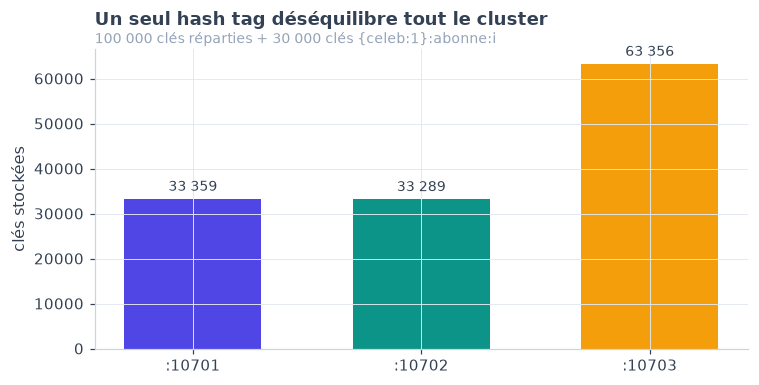

In [14]:
pipe = rc.pipeline()
for i in range(30_000):
    pipe.set(f"{{celeb:1}}:abonne:{i}", 1)
pipe.execute()
celeb_slot = P.redis_slot("{celeb:1}")
sizes = {p: node(p).dbsize() for p in PORTS[:3]}
print(f"slot de {{celeb:1}} : {celeb_slot}, possédé par :{owners3[celeb_slot]} ; "
      f"clés dans ce slot : {node(int(owners3[celeb_slot])).execute_command('CLUSTER', 'COUNTKEYSINSLOT', celeb_slot)}")

fig, ax = plt.subplots(figsize=(7, 3.6))
bars = ax.bar([f":{p}" for p in sizes], sizes.values(), color=[NODE_COLOR[p] for p in sizes], width=0.6)
ax.bar_label(bars, labels=[fmt(v) for v in sizes.values()], padding=3, fontsize=9)
ax.set_ylabel("clés stockées")
ax.set_title("Un seul hash tag déséquilibre tout le cluster")
subtitle(ax, "100 000 clés réparties + 30 000 clés {celeb:1}:abonne:i")
plt.tight_layout(); plt.show()

Un seul slot sur 16 384 contient maintenant plus d'un cinquième des données, et aucun
rééquilibrage n'y peut rien : un slot est l'unité indivisible de déplacement. On
retrouve le dilemme du livre : la clé de partitionnement doit
être assez fine pour répartir la charge, et assez grossière pour garder ensemble ce qui
est lu ensemble.

> **À retenir.** Les hash tags donnent le contrôle du placement (opérations multi-clés,
> transactions locales), au prix d'un risque de point chaud qu'aucun rééquilibrage ne
> corrigera.

## 5. Ajouter un nœud : le rééquilibrage mesuré (sections *Rebalancing Partitions* et *Operations: Automatic or Manual Rebalancing*)

On supprime les clés du compte célèbre (et celles de `{user:42}`) pour repartir d'un cluster équilibré, puis on
ajoute le quatrième nœud. Deux étapes, toutes deux déclenchées **à la main** (Redis
n'automatise pas le rééquilibrage : c'est le choix « humain dans la boucle » du livre) :

1. `--cluster add-node` fait entrer le nœud dans le cluster, sans aucun slot ;
2. `--cluster rebalance --cluster-use-empty-masters` calcule un plan qui donne au
   nouveau venu sa part de slots, prise aux autres, et l'exécute slot par slot.

Entre les deux, il faut **attendre que le gossip ait convergé** : si l'on lance le
rééquilibrage alors que certains nœuds ne connaissent pas encore le nouveau, la
migration échoue (`CLUSTERDOWN`) et laisse un slot à moitié migré, qu'il faut réparer
avec `--cluster fix`. Avant tout, on note le propriétaire de chaque clé.

In [15]:
for p in PORTS[:3]:
    n = node(p)
    while True:
        batch = n.scan(0, match="{celeb:1}:*", count=5000)[1]
        if not batch:
            break
        n.delete(*batch)
n42.delete(*user_keys)
print({p: node(p).dbsize() for p in PORTS[:3]})
before = owners3[key_slot]

cli("--cluster", "add-node", "127.0.0.1:10704", "127.0.0.1:10701")
print(f"le nouveau nœud est connu de tous après {wait_cluster(PORTS):.1f} s")
t0 = time.time()
out = cli("--cluster", "rebalance", "127.0.0.1:10701", "--cluster-use-empty-masters")
print(f"rééquilibrage exécuté en {time.time() - t0:.1f} s")
check = cli("--cluster", "check", "127.0.0.1:10701", check=False)
if "open" in check and "[WARNING]" in check:          # slot resté à moitié migré
    cli("--cluster", "fix", "127.0.0.1:10701")
wait_cluster(PORTS)
owners4 = slot_owners()
after = owners4[key_slot]
slot_ranges()

{10701: 33359, 10702: 33289, 10703: 33352}


le nouveau nœud est connu de tous après 5.1 s


rééquilibrage exécuté en 2.0 s


,premier slot,dernier slot,nœud,slots
0,0,1364,10704,1365
1,1365,5460,10701,4096
2,5461,6826,10704,1366
3,6827,10922,10702,4096
4,10923,12287,10704,1365
5,12288,16383,10703,4096


Le nouveau nœud n'a pas reçu une plage contiguë mais **trois morceaux**, un pris à
chacun des anciens nœuds : chaque ancien cède le bout de sa plage nécessaire pour
revenir à 4 096 slots. Visualisons la carte avant et après.

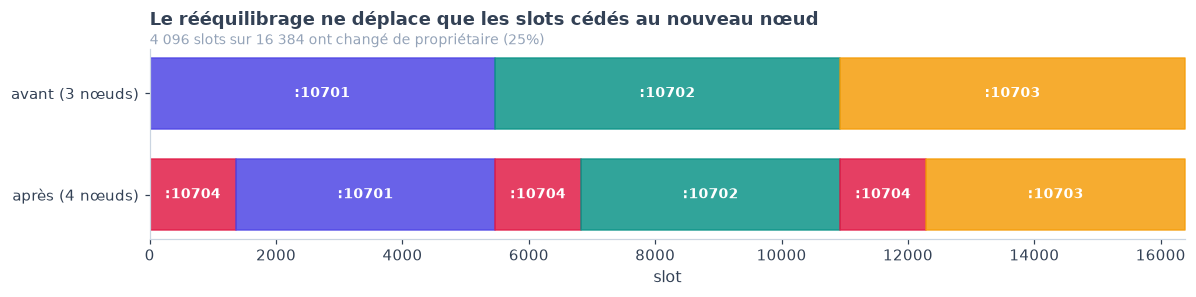

In [16]:
fig, ax = plt.subplots(figsize=(11, 2.8))
for row, (label, own) in enumerate([("avant (3 nœuds)", owners3), ("après (4 nœuds)", owners4)]):
    y = 1 - row
    change = np.flatnonzero(np.diff(own)) + 1
    starts = np.concatenate([[0], change])
    ends = np.concatenate([change, [N_SLOTS]])
    for s, e in zip(starts, ends):
        p = int(own[s])
        ax.broken_barh([(s, e - s)], (y - 0.35, 0.7), color=NODE_COLOR[p], alpha=0.85)
        ax.text((s + e) / 2, y, f":{p}", ha="center", va="center", color="white", fontsize=9, fontweight="bold")
moved_slots = np.flatnonzero(owners3 != owners4)
ax.set_yticks([1, 0], ["avant (3 nœuds)", "après (4 nœuds)"])
ax.set_xlim(0, N_SLOTS)
ax.set_xlabel("slot")
ax.grid(False)
ax.set_title("Le rééquilibrage ne déplace que les slots cédés au nouveau nœud")
subtitle(ax, f"{fmt(moved_slots.size)} slots sur {fmt(N_SLOTS)} ont changé de propriétaire ({moved_slots.size / N_SLOTS:.0%})")
plt.tight_layout(); plt.show()

Comptons maintenant les **clés** qui ont changé de nœud, et comparons au schéma naïf
« haché mod N », qui, en passant de 3 à 4 nœuds, déplacerait toute clé dont le reste
change. Pour ce dernier, on applique `ddia.partitioning.mod_n_assign` aux mêmes clés
(calcul, pas de vrai déplacement).

clés par nœud après rééquilibrage : {10701: 25014, 10702: 24963, 10703: 25001, 10704: 25022}


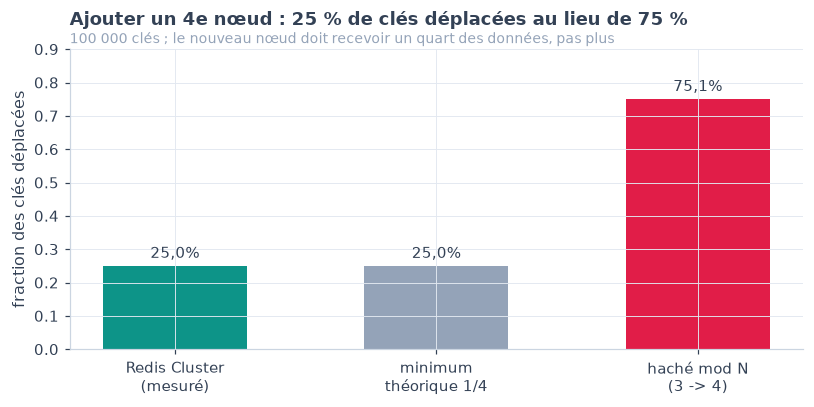

In [17]:
frac_redis = P.moved_fraction(before, after)
ids = np.arange(N_KEYS)
frac_mod = P.moved_fraction(P.mod_n_assign(ids, 3), P.mod_n_assign(ids, 4))
dbsize4 = {p: node(p).dbsize() for p in PORTS}
print("clés par nœud après rééquilibrage :", dbsize4)
assert sum(dbsize4.values()) == N_KEYS and dbsize4[10704] == int((after == 10704).sum())

fig, ax = plt.subplots(figsize=(7.5, 3.8))
vals = [frac_redis, 0.25, frac_mod]
bars = ax.bar(["Redis Cluster\n(mesuré)", "minimum\nthéorique 1/4", "haché mod N\n(3 -> 4)"], vals,
              color=[TEAL, GRAY, ROSE], width=0.55)
ax.bar_label(bars, labels=[f"{v:.1%}".replace(".", ",") for v in vals], padding=3)
ax.set_ylim(0, 0.9)
ax.set_ylabel("fraction des clés déplacées")
ax.set_title("Ajouter un 4e nœud : 25 % de clés déplacées au lieu de 75 %")
subtitle(ax, f"{fmt(N_KEYS)} clés ; le nouveau nœud doit recevoir un quart des données, pas plus")
plt.tight_layout(); plt.show()

La mesure confirme le raisonnement du livre : avec un nombre fixe de
partitions, le rééquilibrage déplace **exactement** ce que le
nouveau nœud doit recevoir (un quart des slots, donc environ un quart des clés, à la
fluctuation près du nombre de clés par slot), alors que le modulo en déplacerait les
trois quarts. Le `DBSIZE` du nouveau nœud correspond bien au nombre de clés dont le
slot lui revient : les données ont réellement voyagé.

> **À retenir.** Dans Redis Cluster, ajouter un nœud revient à lui céder des slots
> entiers ; la quantité de données transférée est la part minimale qui lui revient.

## 6. Migrer un slot pas à pas : la période de bascule (section *Request Routing*)

Le livre pose la question délicate du routage : pendant qu'une partition
passe d'un nœud à l'autre, des requêtes arrivent encore à l'ancien. Redis y répond par
un protocole en quatre temps, que `rebalance` vient d'exécuter des milliers de fois et
que nous allons dérouler à la main sur un seul slot :

1. le destinataire marque le slot `IMPORTING` (il accepte des requêtes pour ce slot,
   mais seulement si elles sont précédées de `ASKING`) ;
2. la source le marque `MIGRATING` (elle sert encore les clés qu'elle a, et répond
   `ASK` pour celles qu'elle n'a plus) ;
3. la source transfère les clés par lots (`MIGRATE`, atomique clé par clé) ;
4. `SETSLOT ... NODE` officialise le nouveau propriétaire ; à partir de là, l'ancien
   répond `MOVED`.

Prenons le slot de `user:1` et transférons-le de son propriétaire vers un autre nœud.

In [18]:
SLOT = P.redis_slot("user:1")
src_port = int(owners4[SLOT])
dst_port = [p for p in PORTS if p != src_port][0]
src, dst = node(src_port), node(dst_port)
src_id, dst_id = src.execute_command("CLUSTER", "MYID"), dst.execute_command("CLUSTER", "MYID")
keys_in_slot = src.execute_command("CLUSTER", "GETKEYSINSLOT", SLOT, 100)
print(f"slot {SLOT} : {len(keys_in_slot)} clés, de :{src_port} vers :{dst_port} -> {keys_in_slot}")

dst.execute_command("CLUSTER", "SETSLOT", SLOT, "IMPORTING", src_id)
src.execute_command("CLUSTER", "SETSLOT", SLOT, "MIGRATING", dst_id)
first, rest = keys_in_slot[:len(keys_in_slot) // 2], keys_in_slot[len(keys_in_slot) // 2:]
src.execute_command("MIGRATE", "127.0.0.1", dst_port, "", 0, 5000, "KEYS", *first)
print("migrées :", first, "| restées sur la source :", rest)

slot 10778 : 6 clés, de :10702 vers :10701 -> ['user:22855', 'user:11896', 'user:33814', 'user:98136', 'user:1', 'user:89177']
migrées : ['user:22855', 'user:11896', 'user:33814'] | restées sur la source : ['user:98136', 'user:1', 'user:89177']


Nous sommes au milieu de la bascule : la moitié des clés du slot est déjà chez le
destinataire. Interrogeons la source et le destinataire pour une clé de chaque moitié.

In [19]:
def try_get(conn, key, asking=False):
    try:
        if asking:
            p = conn.pipeline(transaction=False)
            p.execute_command("ASKING")
            p.get(key)
            return f"servie : {p.execute()[1]!r}"
        return f"servie : {conn.get(key)!r}"
    except MovedError as e:                         # (MovedError hérite d'AskError dans redis-py)
        return f"MOVED {e.slot_id} -> :{e.port}"
    except AskError as e:
        return f"ASK {e.slot_id} -> :{e.port}"


rows = []
for key in [rest[0], first[0]]:
    rows.append({"clé": key, "moitié": "pas encore migrée" if key in rest else "déjà migrée",
                 f"source :{src_port}": try_get(src, key),
                 f"destinataire :{dst_port} sans ASKING": try_get(dst, key),
                 f"destinataire :{dst_port} avec ASKING": try_get(dst, key, asking=True)})
pd.DataFrame(rows).set_index("clé")

,moitié,source :10702,destinataire :10701 sans ASKING,destinataire :10701 avec ASKING
clé,,,,
user:98136,pas encore migrée,servie : 'profil',MOVED 10778 -> :10702,servie : None
user:22855,déjà migrée,ASK 10778 -> :10701,MOVED 10778 -> :10702,servie : 'profil'


Toutes les combinaisons de la période de bascule sont là :

- une clé **pas encore migrée** est servie normalement par la source ;
- pour une clé **déjà migrée**, la source répond `ASK` : « va voir le destinataire,
  pour cette requête seulement » ; contrairement à `MOVED`, le client **ne modifie pas
  sa carte**, car le slot n'a pas encore changé officiellement de propriétaire ;
- le destinataire refuse la clé (`MOVED` vers la source) si on ne lui dit pas `ASKING`,
  et l'accepte sinon : il ne servira un slot `IMPORTING` qu'aux clients explicitement
  envoyés par la source ;
- l'ordre compte : interrogé directement avec `ASKING` pour une clé **pas encore
  migrée**, le destinataire répond « clé absente » (`None`), ce qui serait faux. D'où la
  règle : on va toujours d'abord chez la source, seule à savoir si la clé est déjà
  partie. Ainsi une clé n'est jamais servie depuis deux endroits à la fois.

Le diagramme espace-temps de la lecture d'une clé déjà migrée :

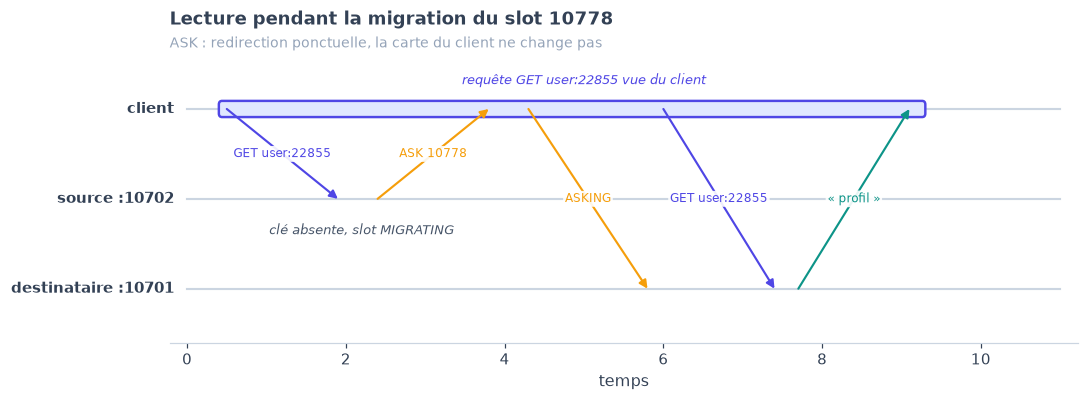

In [20]:
st = SpaceTime(["client", f"source :{src_port}", f"destinataire :{dst_port}"], t_max=11,
               title=f"Lecture pendant la migration du slot {SLOT}",
               subtitle="ASK : redirection ponctuelle, la carte du client ne change pas")
st.op("client", 0.4, 9.3, "", color=INDIGO)
st.note(5.0, "client", f"requête GET {first[0]} vue du client", dy=0.32, color=INDIGO)
st.msg("client", 0.5, f"source :{src_port}", 1.9, f"GET {first[0]}", color=INDIGO)
st.note(2.2, f"source :{src_port}", "clé absente, slot MIGRATING", dy=-0.35)
st.msg(f"source :{src_port}", 2.4, "client", 3.8, f"ASK {SLOT}", color=AMBER)
st.msg("client", 4.3, f"destinataire :{dst_port}", 5.8, "ASKING", color=AMBER)
st.msg("client", 6.0, f"destinataire :{dst_port}", 7.4, f"GET {first[0]}", color=INDIGO)
st.msg(f"destinataire :{dst_port}", 7.7, "client", 9.1, "« profil »", color=TEAL)
st.show()

On termine la migration : transfert du reste des clés, puis `SETSLOT ... NODE` sur
**tous** les nœuds (en pratique, sur les deux protagonistes, le gossip faisant le
reste). Ensuite, la source répond `MOVED`, et notre client corrige sa carte.

In [21]:
src.execute_command("MIGRATE", "127.0.0.1", dst_port, "", 0, 5000, "KEYS", *rest)
for p in PORTS:
    node(p).execute_command("CLUSTER", "SETSLOT", SLOT, "NODE", dst_id)
wait_cluster(PORTS)
print(f"après : source -> {try_get(src, first[0])} ; destinataire -> {try_get(dst, first[0])}")
print("clés du slot sur la source :", src.execute_command("CLUSTER", "COUNTKEYSINSLOT", SLOT),
      "; sur le destinataire :", dst.execute_command("CLUSTER", "COUNTKEYSINSLOT", SLOT))

stale = MiniClient("carte", owners4)                # carte d'avant la migration manuelle
assert all(stale.get(k) == "profil" for k in keys_in_slot)
print(f"client à la carte périmée : {stale.redirects} redirection, {stale.reloads} rechargement de carte")

après : source -> MOVED 10778 -> :10701 ; destinataire -> servie : 'profil'
clés du slot sur la source : 0 ; sur le destinataire : 6
client à la carte périmée : 1 redirection, 1 rechargement de carte


Le protocole répond aux trois questions du livre : **qui décide** (ici l'opérateur, via
`redis-cli` ; Redis n'a pas de coordinateur central, la configuration se propage par
gossip et des numéros d'époque départagent les conflits), **comment le routeur
apprend-il le changement** (par la redirection `MOVED` qui suit la bascule, plutôt que
par une notification), et **que faire des requêtes en vol** (`ASK` et `ASKING` pendant la
fenêtre de migration).

> **À retenir.** La migration d'un slot est découpée pour que, à chaque instant, une
> clé ait un seul nœud autorisé à la servir : `MIGRATING` / `IMPORTING` délimitent la
> période de bascule, `ASK` y redirige sans changer la carte, `MOVED` la clôt.